In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import copy

import scipy.stats as stats
import re

import os
%config InlineBackend.figure_format ='retina'

%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")
import builtins
    
builtins.NAMING = "new"

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *
from RealTrace_paper_analysis.plotting_src.header_settings import *

from RealTrace_paper_analysis.plotting_src.naive_rates import *

from mpl_toolkits.axes_grid1.inset_locator import (inset_axes, InsetPosition,
                                                  mark_inset)
import matplotlib
%config InlineBackend.figure_format ='retina'


header_setting.py: using new naming


## First processing and removal of obvious errors in the input file

Data_Glc_P5ori before filter 16951
after NAN filter 16648
after outlier filter 13960


/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_40903/1994380919.py:37: RuntimeWarning: divide by zero encountered in log
  if not np.all(np.isfinite(np.log(cells[cell]["L"]))):


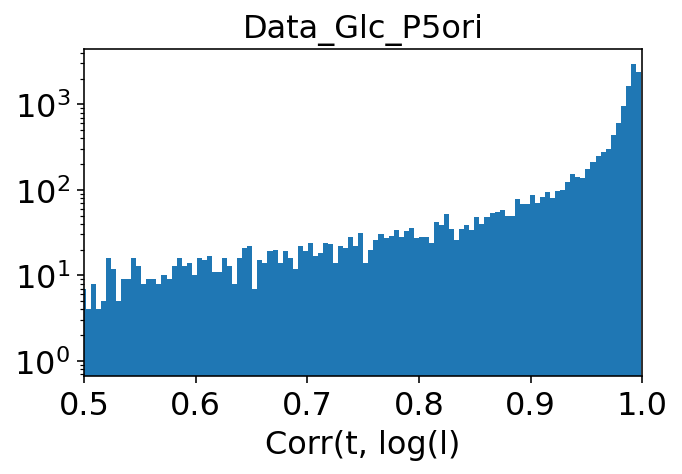

after R2 filter 10144


In [3]:
def read_all_txts(files):
    cells = {}
    for file in files:
        file_prefix = file.split("/")[-1].split("_")[0]
        with open(file, "r", encoding="utf-8") as f:
            for line in f:
                if line.startswith("CELL"):
                    cell_id = file_prefix+"_"+line.strip().replace(":\t", "_")
                    cells[cell_id] = {}
                    current_cell = cell_id
                else:
                    line = line.strip()
                    variable = line.split(":")[0]
                    data = np.array(line.split(":")[1].strip().split("\t")).astype(float)
                    cells[current_cell][variable] = data
    return cells

def filter_extreme_outliers(cells):
    new_cell_dict = {}
    for cell in list(cells.keys()):
        if cells[cell]["L"][0]>cells[cell]["L"][-1]:
            continue
        if np.any(np.abs(np.diff( np.log(cells[cell]["L"]) ))>0.3):
            continue
                    
        if len(cells[cell]["T"])<3:
            continue
        new_cell_dict[cell] = cells[cell]
    return new_cell_dict
    

def filter_nans(cells):
    new_cell_dict = {}
    for cell in list(cells.keys()):
        if not np.all(np.isfinite(cells[cell]["L"])):
            continue
        if not np.all(np.isfinite(np.log(cells[cell]["L"]))):
            continue
        if not np.all(np.isfinite(cells[cell]["F1"])):
            continue
        if not np.all(np.isfinite(np.log(cells[cell]["F1"]))):
            continue
        if np.any(np.diff(cells[cell]["T"])==0):
            continue
        new_cell_dict[cell] = cells[cell]
    return new_cell_dict


def filter_by_r2(cells, r2, only_positive=True):
    new_cell_dict = {}
    for cell in list(cells.keys()):
        r = np.corrcoef(cells[cell]["T"], np.log(cells[cell]["L"]))[0,1]
        if r<0:
            continue
        if r**2 < r2:
            continue
        new_cell_dict[cell] = cells[cell]
    return new_cell_dict
    
def get_n_cells(cells, n=1000):
    new_cell_dict = {}
    for cell in list(cells.keys())[:n]:
        new_cell_dict[cell] = cells[cell]
    return new_cell_dict
    

def r2_hist(cells, title=None):
    fig, ax = plt.subplots(1, 1, figsize=(5, 3))
    ax.set_title(title)
    rs = [np.corrcoef(cells[cell]["T"], np.log(cells[cell]["L"]))[0,1] for cell in list(cells.keys())]
    ax.hist(rs, bins="auto")
    ax.set_yscale("log")
    ax.set_xlabel("Corr(t, log(l)")
    ax.set_xlim(0.5, 1)
    plt.show()
    
def process_raw_data(raw_data, outfile):

    dataset = pd.DataFrame()
    for cell in raw_data.keys():        
        cell_df = pd.DataFrame(raw_data[cell])
        cell_df["cell_id"] = cell
        dataset = pd.concat([dataset, cell_df], ignore_index=True)
        
    dataset["parent_id"] = -1
    dataset.to_csv(outfile)
    return dataset


    
directories = ["../../ecoli_other_labs/Kennard2016/Data_Glc_P5ori/Raw"]

data_sets =[]
raw_datas =[]
for directory in directories:
    filenames = get_suffix_files(directory, suffix='txt') 
    raw_data = read_all_txts( filenames)
    print(directory.split("/")[-2], "before filter", len(raw_data))
    
    raw_data = filter_nans(raw_data)
    print("after NAN filter", len(raw_data))

    
    raw_data = filter_extreme_outliers(raw_data)
    print("after outlier filter", len(raw_data))
    
    r2_hist(raw_data, title =directory.split("/")[-2])
    raw_data = filter_by_r2(raw_data, 0.9, only_positive=True)
    print("after R2 filter", len(raw_data))

    raw_data = get_n_cells(raw_data, n=1000)
    raw_datas.append(raw_data)
    outfile = directory.split("/Raw")[0] + "_processed_filter_r2.csv"
    dataset = process_raw_data(raw_data, outfile)
    data_sets.append(dataset)



In [4]:
for file in directories: 
    print(file, "\n")
    out_dir = os.path.join(*file.split("/")[:-2], "RealTrace_out_filter_r2")
    outfile = file.replace("/Raw", "_processed_filter_r2.csv")
    
    param_file = outfile.replace("_filter_r2.csv", "_parameters.txt")
    config_file = os.path.join(*file.split("/")[:-2], "csv_config.txt")
    
    run_cmd = "../../RealTrace/bin/RealTrace" + \
            " -c " + config_file + \
            " -b " + param_file + \
            " -t " + str(1e-40) + \
            " -i " + outfile + \
            " -o " + out_dir + \
            " -space log" +\
            " -m -p"
    print("run: -> \n", run_cmd)
    s = subprocess.run(run_cmd, capture_output=True, shell=True)
    print(s)


../../ecoli_other_labs/Kennard2016/Data_Glc_P5ori/Raw 

run: -> 
 ../../RealTrace/bin/RealTrace -c ../../ecoli_other_labs/Kennard2016/csv_config.txt -b ../../ecoli_other_labs/Kennard2016/Data_Glc_P5ori_processed_parameters.txt -t 1e-40 -i ../../ecoli_other_labs/Kennard2016/Data_Glc_P5ori_processed_filter_r2.csv -o ../../ecoli_other_labs/Kennard2016/RealTrace_out_filter_r2 -space log -m -p
CompletedProcess(args='../../RealTrace/bin/RealTrace -c ../../ecoli_other_labs/Kennard2016/csv_config.txt -b ../../ecoli_other_labs/Kennard2016/Data_Glc_P5ori_processed_parameters.txt -t 1e-40 -i ../../ecoli_other_labs/Kennard2016/Data_Glc_P5ori_processed_filter_r2.csv -o ../../ecoli_other_labs/Kennard2016/RealTrace_out_filter_r2 -space log -m -p', returncode=0, stdout=b"Running... \nTemporary log file '../../ecoli_other_labs/Kennard2016/RealTrace_out_filter_r2/Data_Glc_P5ori_processed_filter_r2.log' created\nDone. Log file: ../../ecoli_other_labs/Kennard2016/RealTrace_out_filter_r2/Data_Glc_P5ori_pro

## First run on unfiltered data

In [10]:
for file in directories: 
    print(file, "\n")
    out_dir = os.path.join(*file.split("/")[:-2], "RealTrace_out")
    outfile = file.replace("/Raw", "_processed.csv")
    
    param_file = outfile.replace(".csv", "_parameters.txt")
    config_file = os.path.join(*file.split("/")[:-2], "csv_config.txt")
    
    run_cmd = "../../RealTrace/bin/RealTrace" + \
            " -c " + config_file + \
            " -b " + param_file + \
            " -t " + str(1e-40) + \
            " -i " + outfile + \
            " -o " + out_dir + \
            " -space log" +\
            " -m -p"
    print("run: -> \n", run_cmd)
    s = subprocess.run(run_cmd, capture_output=True, shell=True)
    print(s)


../../ecoli_other_labs/Kennard2016/Data_RDM_P5ori/Raw 

run: -> 
 ../../RealTrace/bin/RealTrace -c ../../ecoli_other_labs/Kennard2016/csv_config.txt -b ../../ecoli_other_labs/Kennard2016/Data_RDM_P5ori_processed_parameters.txt -t 1e-40 -i ../../ecoli_other_labs/Kennard2016/Data_RDM_P5ori_processed.csv -o ../../ecoli_other_labs/Kennard2016/RealTrace_out -space log -m -p
CompletedProcess(args='../../RealTrace/bin/RealTrace -c ../../ecoli_other_labs/Kennard2016/csv_config.txt -b ../../ecoli_other_labs/Kennard2016/Data_RDM_P5ori_processed_parameters.txt -t 1e-40 -i ../../ecoli_other_labs/Kennard2016/Data_RDM_P5ori_processed.csv -o ../../ecoli_other_labs/Kennard2016/RealTrace_out -space log -m -p', returncode=0, stdout=b"Running... \nTemporary log file '../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_RDM_P5ori_processed.log' created\nDone. Log file: ../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_RDM_P5ori_processed_success.log\n", stderr=b'')
../../ecoli_other_labs/Kennard2016/

In [2]:
# color_by_condition_Kennard = {'Glc': "tab:olive",
#                             'CAA': "tab:green",
#                             'RDM': "tab:blue"}


# prediction_files = get_suffix_files("../../ecoli_other_labs/Kennard2016/RealTrace_out/", suffix='prediction.csv') 
# for i in range(3):
#     print(prediction_files[i])
#     _=  plot_predictions(prediction_files[i],
#                         start=1, stop=100, step=1, 
#                         time_unit=('min', 1), 
#                         show=True)

## Filter segmentation errors

../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_CAA_P5ori_processed_f8_b0123457_prediction.csv


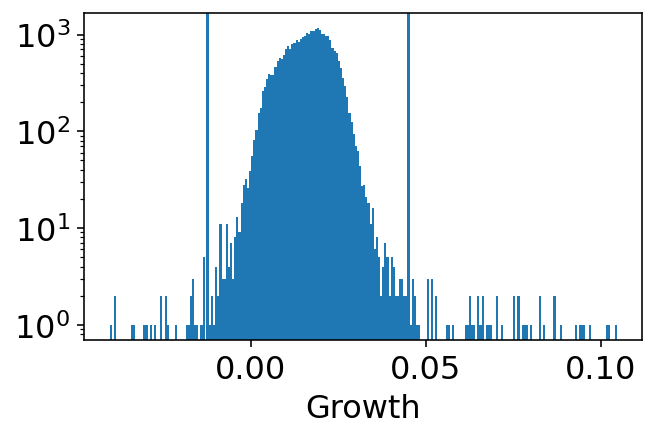

../../ecoli_other_labs/Kennard2016/Data_CAA_P5ori_cleaned.csv
14
986
../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_Glc_P5ori_processed_f8_b0123457_prediction.csv


/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_27077/3695250752.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df["L"] = np.exp(new_df["log_length"])
/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_27077/3695250752.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df["T"] = new_df["time"]
/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_27077/3695250752.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try usi

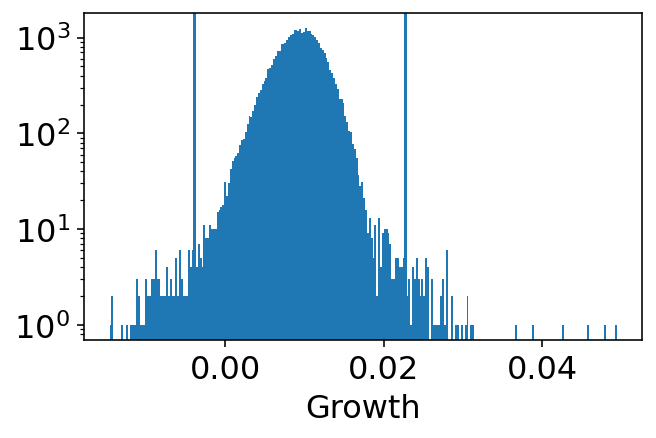

../../ecoli_other_labs/Kennard2016/Data_Glc_P5ori_cleaned.csv
42
958
../../ecoli_other_labs/Kennard2016/RealTrace_out/Data_RDM_P5ori_processed_f8_b0123457_prediction.csv


/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_27077/3695250752.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df["L"] = np.exp(new_df["log_length"])
/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_27077/3695250752.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df["T"] = new_df["time"]
/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_27077/3695250752.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try usi

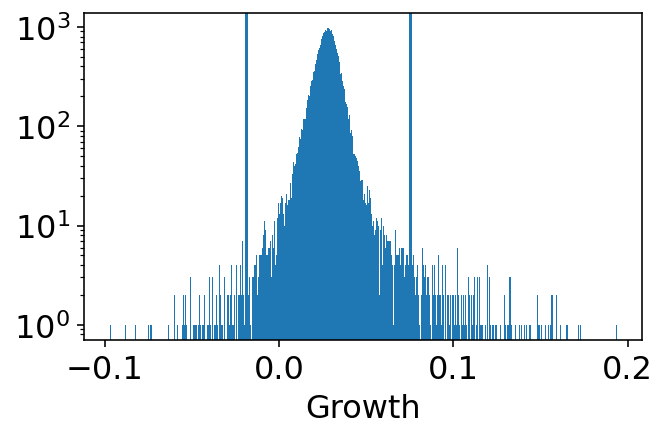

../../ecoli_other_labs/Kennard2016/Data_RDM_P5ori_cleaned.csv
93
907


/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_27077/3695250752.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df["L"] = np.exp(new_df["log_length"])
/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_27077/3695250752.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df["T"] = new_df["time"]
/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_27077/3695250752.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try usi

In [109]:
def plot_growth_hist(df):
    fig, ax = plt.subplots(1, 1, figsize=(5, 3))
    # ax.set_title(title)
    ax.hist(df["mean_l"], bins="auto")
    mean = np.mean(df["mean_l"])
    sd = np.std(df["mean_l"])
    ax.axvline(mean-4*sd)
    ax.axvline(mean+4*sd)
    
    ax.set_yscale("log")
    ax.set_xlabel("Growth")
    # ax.set_xlim(0.5, 1)
    plt.show()

def filter_cells_by_growth_outlier(df, n_std):
    mean = np.mean(df["mean_l"])
    sd = np.std(df["mean_l"])
    lb = mean - n_std*sd
    ub = mean + n_std*sd    
    too_low =  df[df["mean_l"]<lb]["cell_id"]
    too_high = df[df["mean_l"]>ub]["cell_id"]
    cell_ids = np.unique(np.append(too_low, too_high))
    print(len(cell_ids))
    
    new_df = df[~df["cell_id"].isin(cell_ids)] 
    print(len(np.unique(new_df["cell_id"])))
    
    new_df["L"] = np.exp(new_df["log_length"])
    new_df["T"] = new_df["time"]
    # new_df["F1"] = new_df["fp"]
    new_df["dummy_gfp"] = np.random.normal(loc=0, scale=1e-3, size=len(new_df["time"]))
    # new_df = new_df.iloc[::3, :]
    return new_df[["cell_id", "parent_id", "L", "T", "dummy_gfp"]]

    
for pf in prediction_files:
    print(pf)
    prediction_processed_df = pd.read_csv(pf, skiprows=13)
    plot_growth_hist(prediction_processed_df)
    new_out = os.path.join(*pf.split("/")[:-2]) + "/" + pf.split("/")[-1].split("_pro")[0] +"_cleaned.csv"
    print(new_out)
    filter_cells_by_growth_outlier(prediction_processed_df, 4.).to_csv(new_out)


In [130]:
for file in directories: 
    print(file, "\n")
    out_dir = os.path.join(*file.split("/")[:-2], "RealTrace_out_cleaned")
    outfile = file.replace("/Raw", "_cleaned.csv")
    
    param_file = outfile.replace("_cleaned.csv", "_processed_parameters.txt")
    param_file = os.path.join(*file.split("/")[:-2], "parameters.txt")

    
    config_file = os.path.join(*file.split("/")[:-2], "csv_config_dummy_gfp.txt")
    
    run_cmd = "../../RealTrace/bin/RealTrace" + \
            " -c " + config_file + \
            " -b " + param_file + \
            " -t " + str(1e-40) + \
            " -i " + outfile + \
            " -o " + out_dir + \
            " -noise const" +\
            " -n 1" +\
            " -s -m -p"
    print("run: -> \n", run_cmd)
    # s = subprocess.run(run_cmd, capture_output=True, shell=True)
    # print(s)


../../ecoli_other_labs/Kennard2016/Data_RDM_P5ori/Raw 

run: -> 
 ../../RealTrace/bin/RealTrace -c ../../ecoli_other_labs/Kennard2016/csv_config_dummy_gfp.txt -b ../../ecoli_other_labs/Kennard2016/parameters.txt -t 1e-40 -i ../../ecoli_other_labs/Kennard2016/Data_RDM_P5ori_cleaned.csv -o ../../ecoli_other_labs/Kennard2016/RealTrace_out_cleaned -noise const -n 1 -s -m -p
../../ecoli_other_labs/Kennard2016/Data_CAA_P5ori/Raw 

run: -> 
 ../../RealTrace/bin/RealTrace -c ../../ecoli_other_labs/Kennard2016/csv_config_dummy_gfp.txt -b ../../ecoli_other_labs/Kennard2016/parameters.txt -t 1e-40 -i ../../ecoli_other_labs/Kennard2016/Data_CAA_P5ori_cleaned.csv -o ../../ecoli_other_labs/Kennard2016/RealTrace_out_cleaned -noise const -n 1 -s -m -p
../../ecoli_other_labs/Kennard2016/Data_Glc_P5ori/Raw 

run: -> 
 ../../RealTrace/bin/RealTrace -c ../../ecoli_other_labs/Kennard2016/csv_config_dummy_gfp.txt -b ../../ecoli_other_labs/Kennard2016/parameters.txt -t 1e-40 -i ../../ecoli_other_labs/Kennard